In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
path = Path.cwd().parent.parent/"raw_data/data.xlsx"
astronauts = pd.read_excel(path, sheet_name="Astronauts")

In [32]:
# Estimate annual population. First 3 year an additional 100 people in each mission after that the next 2 have
# 1000 people and after that the growth jumps to 10000 per 18 months 
# after the first mission only 50% of population will be couples already

avg_birth_rate = 0.04
avg_death_rate = 0.01
marriege_rate = 0.14
couples = 50
population = 100
couples = population * 0.5
singles = 0
avg_annual_mission_size_3_years = 100
avg_annual_mission_size_5_years = 1000
avg_annual_mission_size_beyond_5_years = 10000
population_statistics = {}

for i in range(0, 520, 18):
    # Measuring in months due to the 18 month travel window
    if i <18:
        print(f"Year {round(i/12)} - Population: {round(population)}, Couples: {couples}, Singles: {singles}")
        metrics = [round(population), round(couples), round(singles)]
        population_statistics[i] = metrics

    else: 

        if i > 18 and i < 37:
            population = (couples + (couples * avg_birth_rate)) * 2 - (population * avg_death_rate) + (avg_annual_mission_size_3_years)
            couples += avg_annual_mission_size_3_years / 2
            
        elif i < 65:
            population = (couples + (couples * avg_birth_rate)) * 2 - (population * avg_death_rate) + (avg_annual_mission_size_5_years)
            couples += avg_annual_mission_size_5_years * marriege_rate

        else:
            population = (couples + (couples * avg_birth_rate)) * 2 - (population * avg_death_rate) + (avg_annual_mission_size_beyond_5_years)
            couples += avg_annual_mission_size_beyond_5_years * marriege_rate

        singles = population - (couples * 2)
        metrics = [round(population), round(couples), round(singles)]
        population_statistics[i] = metrics
        print(f"Year {round(i/12)} - Population: {round(population)}, Couples: {round(couples)}, Singles: {round(singles)}")  

Year 0 - Population: 100, Couples: 50.0, Singles: 0
Year 2 - Population: 1103, Couples: 190, Singles: 723
Year 3 - Population: 484, Couples: 240, Singles: 4
Year 4 - Population: 1494, Couples: 380, Singles: 734
Year 6 - Population: 10775, Couples: 1780, Singles: 7215
Year 8 - Population: 13595, Couples: 3180, Singles: 7235
Year 9 - Population: 16478, Couples: 4580, Singles: 7318
Year 10 - Population: 19362, Couples: 5980, Singles: 7402
Year 12 - Population: 22245, Couples: 7380, Singles: 7485
Year 14 - Population: 25128, Couples: 8780, Singles: 7568
Year 15 - Population: 28011, Couples: 10180, Singles: 7651
Year 16 - Population: 30894, Couples: 11580, Singles: 7734
Year 18 - Population: 33777, Couples: 12980, Singles: 7817
Year 20 - Population: 36661, Couples: 14380, Singles: 7901
Year 21 - Population: 39544, Couples: 15780, Singles: 7984
Year 22 - Population: 42427, Couples: 17180, Singles: 8067
Year 24 - Population: 45310, Couples: 18580, Singles: 8150
Year 26 - Population: 48193, Co

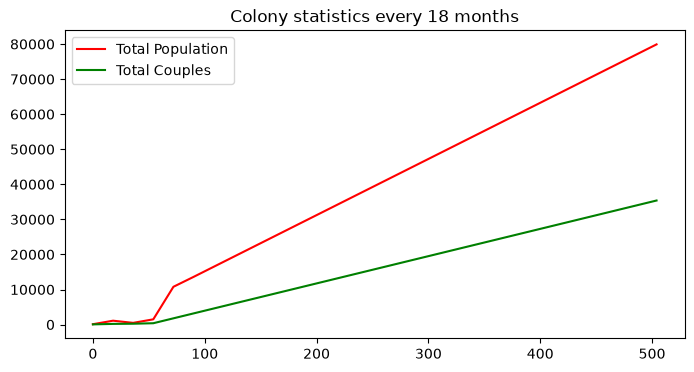

In [39]:
people = [value[0] for value in population_statistics.values()]
couples = [value[1] for value in population_statistics.values()]
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(population_statistics.keys(), people, color='red', label='Total Population')
ax.plot(population_statistics.keys(), couples, color='green', label='Total Couples')
ax.set_title("Colony statistics every 18 months")
ax.legend(loc="upper left")
plt.show()
